# In-depth analysis 

In [1]:
import math
from collections import Counter

import pandas as pd
import numpy as np
import sqlite3
import matplotlib.pyplot as plt
from matplotlib.lines import Line2D
from matplotlib.patches import Patch
from nltk import FreqDist
from nltk.tokenize import word_tokenize
from nltk.stem import WordNetLemmatizer

In [3]:
df = pd.read_pickle("C:\Data_Projects\Project_3_Data4401\processed_reviews.pkl")
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 169613 entries, 0 to 169612
Data columns (total 31 columns):
 #   Column                 Non-Null Count   Dtype  
---  ------                 --------------   -----  
 0   review_id              169613 non-null  int64  
 1   source                 169613 non-null  str    
 2   country                169553 non-null  str    
 3   province               169553 non-null  str    
 4   region_1               141654 non-null  str    
 5   region_2               66852 non-null   str    
 6   winery                 169613 non-null  str    
 7   variety                169612 non-null  str    
 8   designation            119494 non-null  str    
 9   title                  119976 non-null  str    
 10  points                 169613 non-null  int64  
 11  price                  156797 non-null  float64
 12  description            169613 non-null  str    
 13  taster_name            95063 non-null   str    
 14  taster_twitter_handle  90534 non-null   str    

In [ ]:
df_critic = df["taster_name"].fillna("unkown").value_counts()
print(df_critic)

taster_name
unkown                74550
Roger Voss            23560
Michael Schachner     14045
Kerin O’Keefe          9694
Paul Gregutt           8868
Virginie Boone         8707
Matt Kettmann          5729
Joe Czerwinski         4766
Sean P. Sullivan       4460
Anna Lee C. Iijima     4017
Jim Gordon             3766
Anne Krebiehl MW       3289
Lauren Buzzeo          1700
Susan Kostrzewa        1023
Mike DeSimone           461
Jeff Jenssen            436
Alexander Peartree      383
Carrie Dykes            129
Fiona Adams              24
Christina Pickard         6
Name: count, dtype: int64


# Critics + Country + Red Wine

In [17]:
df_critic_red = df[df["color"] == "red"]
df_critic_red["taster_name"] = df_critic_red["taster_name"].fillna("unknown")
df_critic_cont_red = (df_critic_red.groupby(["country", "taster_name"])
                      .size()
                      .reset_index(name="num_reviews")
                      .sort_values(["country", "num_reviews"], ascending=[True, False]))
df_critic_cont_red

,country,taster_name,num_reviews
0,Argentina,Michael Schachner,2757
1,Argentina,unknown,1527
4,Australia,unknown,1620
3,Australia,Joe Czerwinski,1224
2,Australia,Christina Pickard,1
...,...,...,...
113,US,Christina Pickard,2
120,US,Roger Voss,1
125,Ukraine,Jeff Jenssen,3
126,Uruguay,Michael Schachner,85


In [19]:
df_critic_cont_red.to_csv("critic_counts_red.csv", index=False, encoding="utf-8-sig")

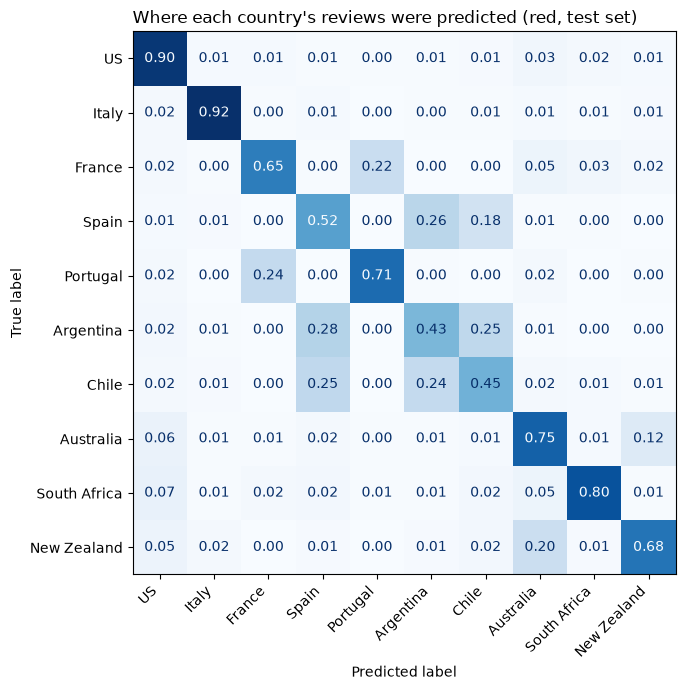

# Courtesy of Power Bi
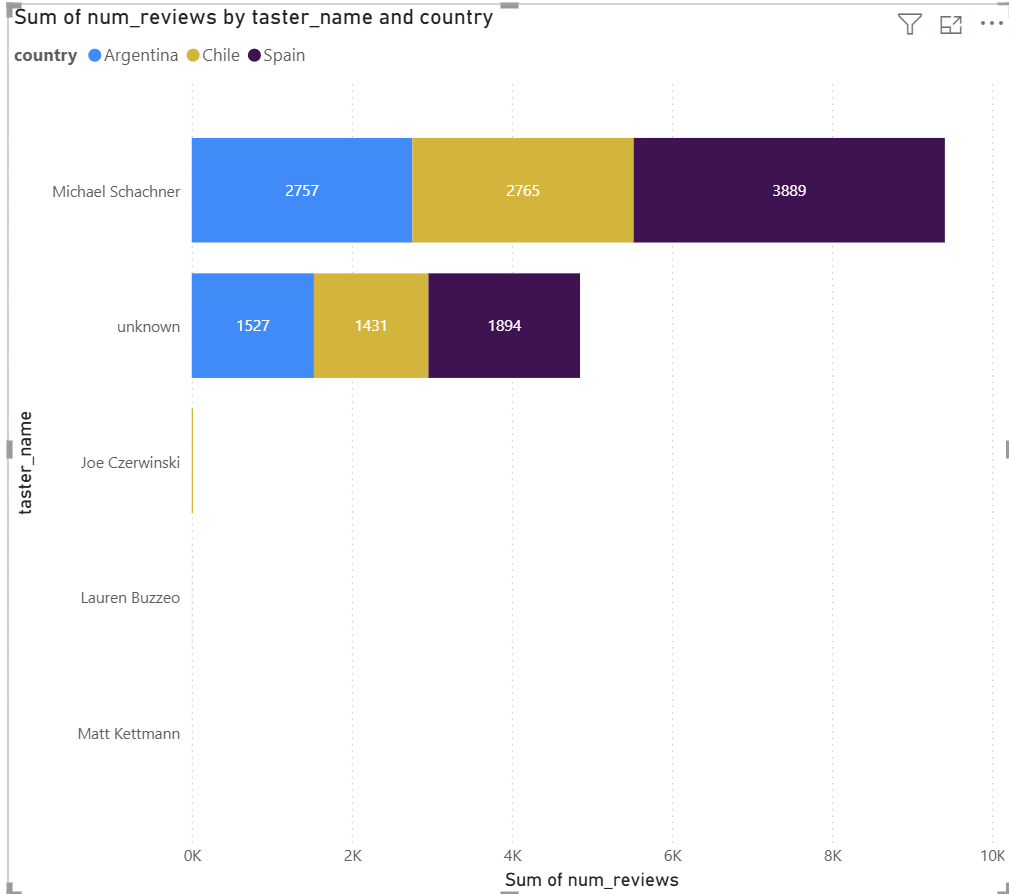
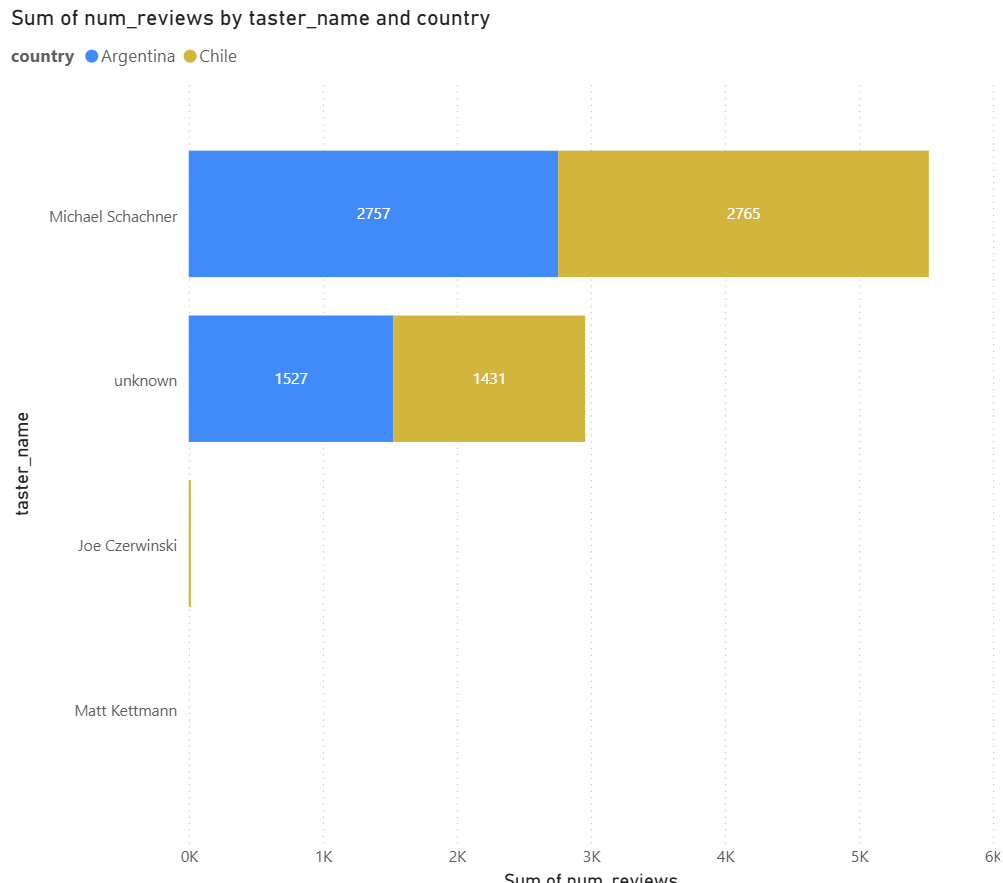

This may explain why our model struggle to recall or differentiate reviews about red wine from chille or Argentina because of the vast majority of reviews that were written by **Michael Schachner**. Thus the styling and usage of words describing a red wine may be biased based off of the way Michael Schachner writes. 

However, its hard to determine if this is the cause due to the unknown tasters that are present within the data set. Therefore, we have an idea now that our data may be influenced and bias towards a tater's words. If Michael Schachner makes majority of the reviews for certain countries, the tatste of red wines within Argentina and Chile may just be based off of his taste and not a reflection of how the wine tastes.

# Plan 
**Goal** To be able to see if their is a unique style that is being detected within the review text data that is confusing our model from being able to differentiate the two country's wine. 

1. Training a model only using Schancher's reviews of Argentina, Chile and Spain; this way we can run the model on the same writer and see if their writing really is able to be differentiated based of descriptions exclusive to a country. 
2. Find signature-words (common and repeated words exclusive to the writer) and remove them to see if our model can better identify them. 

In [24]:
import re
from functools import lru_cache # essentially to keep track of our results from calling a function
from sklearn.feature_extraction.text import CountVectorizer, TfidfVectorizer, ENGLISH_STOP_WORDS
from sklearn.linear_model import LogisticRegression 
from sklearn.metrics import classification_report, ConfusionMatrixDisplay
from data_processing import WINE_WORDS

In [25]:
lemmatizer = WordNetLemmatizer()
TOKEN_PATTERN = r"(?u)\b[a-z][a-z'-]+\b"

@lru_cache(maxsize=None)
def lemma(word):
    return lemmatizer.lemmatize(word)

def lemma_tokenizer(text):
    return [lemma(t) for t in re.findall(TOKEN_PATTERN, text)]


# ------ Same thing from Part 2 -----
NEGATIONS = {"not", "no", "nor", "without"}
EDGE_STOPS = (set(ENGLISH_STOP_WORDS) - NEGATIONS) | WINE_WORDS
EDGE_STOPS |= {lemma(w) for w in EDGE_STOPS} # has -> ha, was -> wa, does -> doe

COUNTRY_WORDS = {
    "american", "italian", "spanish", "chilean", "australian", "aussie",
    "argentine", "argentinean", "argentinian", "portuguese", "african",
    "european", "europe", "californian", "oregonian", "tuscan", "sicilian",
    "burgundian", "alsatian", "sardinian", "patagonian", "galician", "catalan",
    "iberian", "iberia", "umbrian", "piedmontese", "provencal", "calabrian",
    "venetian", "lombard", "bordelais", "castilian", "french", "old-world", "new-world",
}
BOILERPLATE = {"varietyname", "drink"} | COUNTRY_WORDS

def get_text(d):
    return (d["description_masked"].str.lower()
              .str.replace(r"\b(french|american|hungarian)\s+oak\b", "oak", regex=True))

# Building the Subsets (Argentina, Chile, and Spain)

In [26]:
subset = ["Argentina", "Chile", "Spain"]

df_three = df[(df["color"] == "red") & (df["category"] == "still") & (df["country"].isin(subset))].copy()
df_three["taster_name"] = df_three["taster_name"].fillna("unknown")

place_words = set()
for col in ["country", "province", "region_1", "region_2"]:
    for name in df_three[col].dropna().unique():
        place_words.update(lemma_tokenizer(name.lower()))

def keep_phrase(phrase):
    words = phrase.split()
    if words[0] in EDGE_STOPS or words[-1] in EDGE_STOPS:
        return False
    if "old world" in phrase or "new world" in phrase:
        return False
    return not any(w in BOILERPLATE or w in place_words for w in words)

# Model Build (To test Michael Schachner)

In [29]:
def build_vectorizer(train_text, ngram_range, min_df=10):
    counter = CountVectorizer(ngram_range=ngram_range, min_df=min_df,
                              tokenizer=lemma_tokenizer, token_pattern=None)
    counter.fit(train_text)
    vocab = sorted(p for p in counter.vocabulary_ if keep_phrase(p))
    return TfidfVectorizer(ngram_range=ngram_range, vocabulary=vocab,
                           tokenizer=lemma_tokenizer, token_pattern=None, sublinear_tf=True)

def run_country_model(data, title):
    train = data[data["split"] == "train"]
    test  = data[data["split"].isin(["val", "test"])]

    vec = build_vectorizer(get_text(train), (1, 3))
    X_tr = vec.fit_transform(get_text(train))
    X_te = vec.transform(get_text(test))

    model = LogisticRegression(class_weight="balanced", max_iter=2000).fit(X_tr, train["country"])
    pred = model.predict(X_te)

    print(f"{title}  (train={len(train):,}, test={len(test):,}, features={X_tr.shape[1]:,})")
    print(classification_report(test["country"], pred, digits=3))

    fig, ax = plt.subplots(figsize=(5, 4.5))
    ConfusionMatrixDisplay.from_predictions(test["country"], pred, labels=subset, normalize="true",
                                            values_format=".2f", cmap="Blues", colorbar=False, ax=ax)
    ax.set_title(title, loc="left", fontsize=11)
    plt.tight_layout()
    plt.show()
    return vec, model


Schachner only: red wine, 3 countries  (train=6,556, test=2,855, features=2,097)
              precision    recall  f1-score   support

   Argentina      0.423     0.451     0.436       839
       Chile      0.511     0.508     0.510       841
       Spain      0.593     0.569     0.580      1175

    accuracy                          0.516      2855
   macro avg      0.509     0.509     0.509      2855
weighted avg      0.519     0.516     0.517      2855



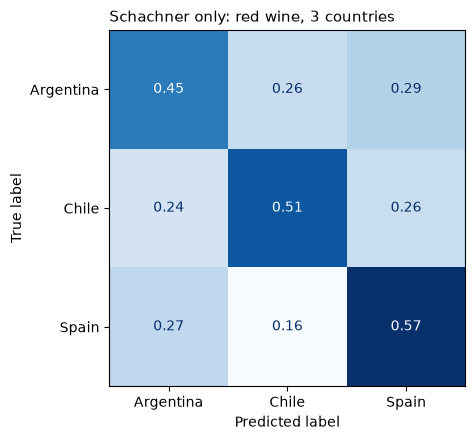

In [30]:
schachner = df_three[df_three["taster_name"] == "Michael Schachner"]
vec_s, model_s = run_country_model(schachner, "Schachner only: red wine, 3 countries")

Unknown critics: red, 3 countries  (train=3,359, test=1,493, features=1,229)
              precision    recall  f1-score   support

   Argentina      0.427     0.462     0.444       457
       Chile      0.467     0.506     0.486       419
       Spain      0.558     0.493     0.523       617

    accuracy                          0.487      1493
   macro avg      0.484     0.487     0.484      1493
weighted avg      0.492     0.487     0.488      1493



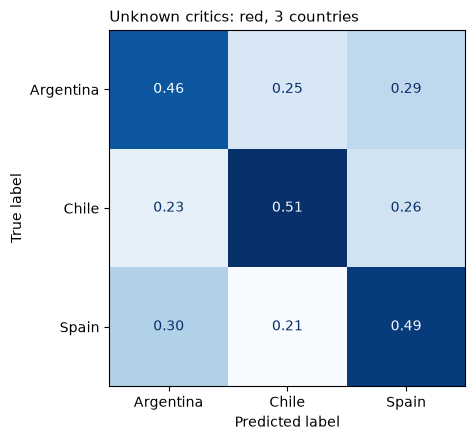

In [31]:
unknown = df_three[df_three["taster_name"] == "unknown"]
vec_u, model_u = run_country_model(unknown, "Unknown critics: red, 3 countries")

# Results 
Restricting the data to Michael Schachner's reviews, so that every review shares one writing style, barely changed the results. The model reached 51.6% accuracy (macro-F1 0.51) at separating Argentina, Chile and Spain, against 33% for random guessing. Running the same model on reviews with no critic name gave almost the same result (48.7%, macro-F1 0.48). Recall for Argentina (~0.45) and Chile (~0.51) was close to what the main red-wine model achieved, so mixing critics was not what caused their confusion.

Spain was only slightly easier to identify (recall 0.57). This suggests that, with grape and place names removed, all three countries' red wines are described in largely the same vocabulary, meaning their wines may share similar tastes.

Limitation: the "unknown" reviews have no critic name, but they come from the same publication and may include the same critics, Schachner among them. They are not a fully independent comparison. A stronger check is whether a single critic who covers clearly different wines (e.g. Joe Czerwinski: Australia vs. New Zealand) produces more separable descriptions.